<a href="https://colab.research.google.com/github/preethikris/BMSCE-DATA-VISUALIZATION/blob/main/DATA_VISUALIZATION_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# ==========================================
# TASK 4: High-Dimensional EDA & PCA (Google Colab)
# Dataset: UCI Wine Dataset (Direct URL)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

In [2]:
# 1. Load dataset directly from UCI Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
columns = [
    "cultivar_id", "alcohol", "malic_acid", "ash", "alcalinity_of_ash",
    "magnesium", "total_phenols", "flavanoids", "nonflavanoid_phenols",
    "proanthocyanins", "color_intensity", "hue", "od280_od315", "proline"
]
df_wine = pd.read_csv(url, header=None, names=columns)
df_wine["cultivar"] = df_wine["cultivar_id"].map({
    1: "Cultivar 1", 2: "Cultivar 2", 3: "Cultivar 3"
})

features = columns[1:]
X = df_wine[features]
y = df_wine["cultivar"]

print(f"Dataset Shape: {df_wine.shape}")
print("Class Distribution:\n", y.value_counts(), "\n")

Dataset Shape: (178, 15)
Class Distribution:
 cultivar
Cultivar 2    71
Cultivar 1    59
Cultivar 3    48
Name: count, dtype: int64 



In [3]:
# 2. Parallel Coordinates Plot (Min-Max scaled so all 13 features share [0, 1])
scaler_minmax = MinMaxScaler()
df_norm = pd.DataFrame(scaler_minmax.fit_transform(X), columns=features)
df_norm["cultivar_id"] = df_wine["cultivar_id"]

fig_parallel = px.parallel_coordinates(
    df_norm,
    color="cultivar_id",
    dimensions=features,
    color_continuous_scale=px.colors.diverging.Tealrose,
    title="Parallel Coordinates Plot of 13 Normalized Wine Features (Colored by Cultivar)"
)
fig_parallel.update_layout(height=550)
fig_parallel.show()

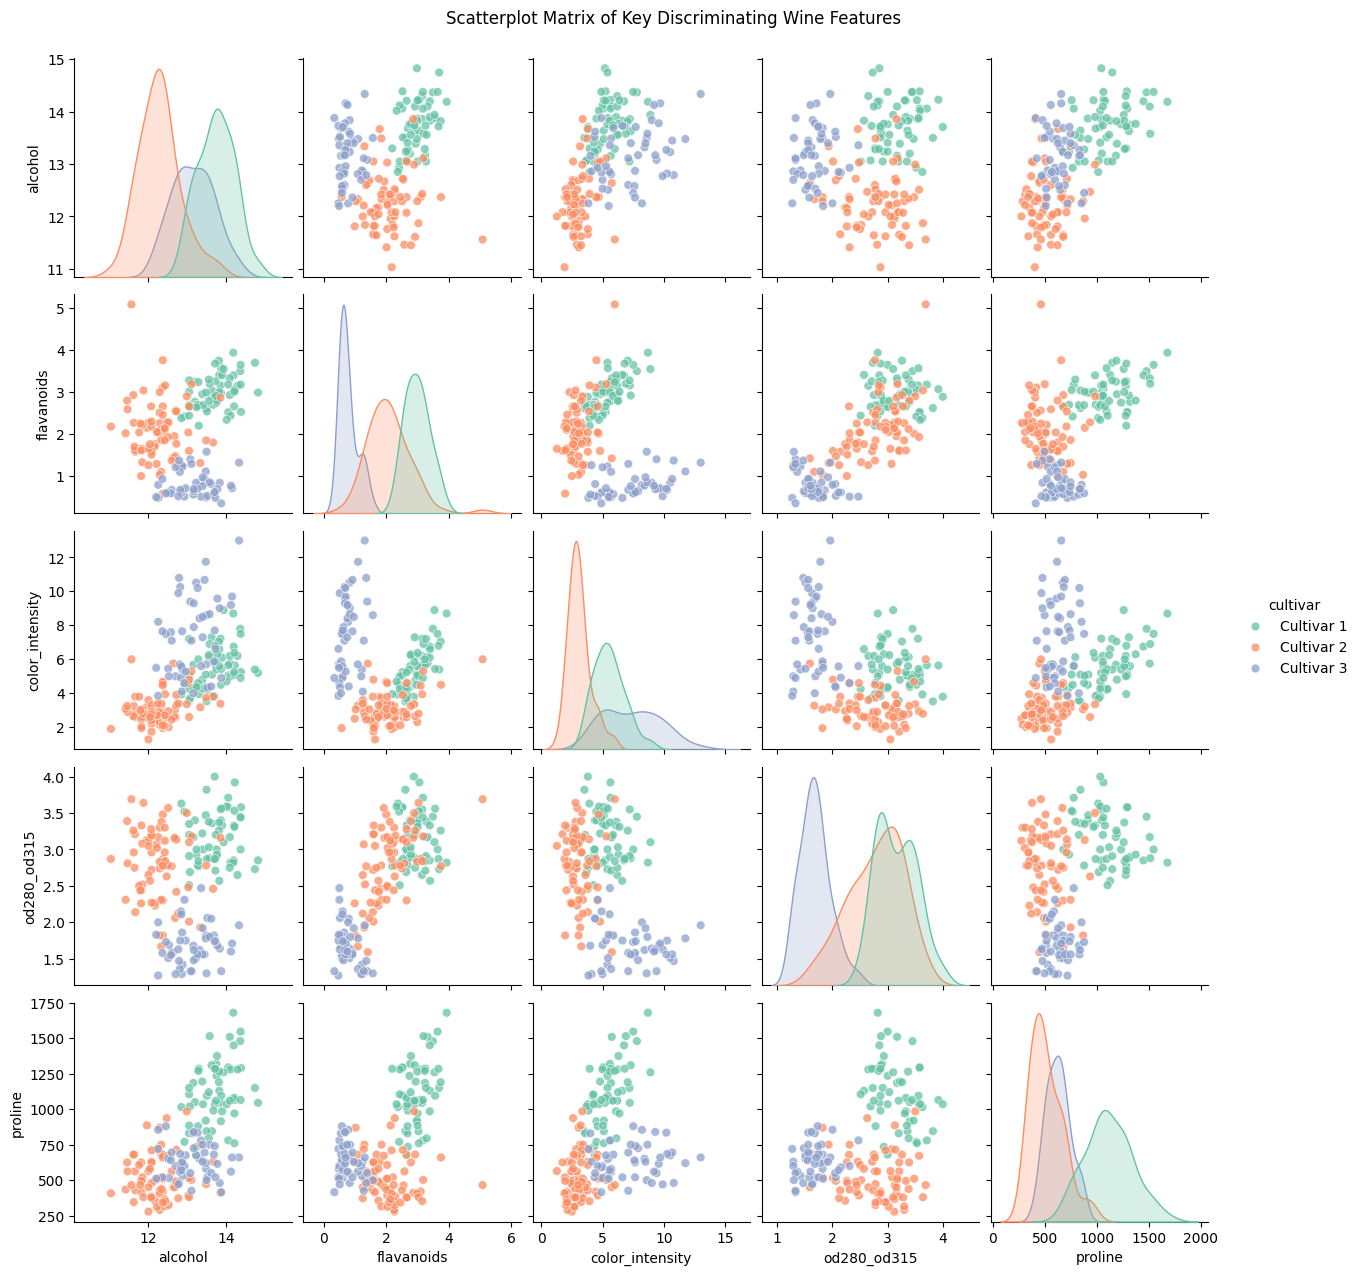

In [4]:
# 3. Scatterplot Matrix (SPLOM) on 5 high-discriminating chemical features
selected_features = ["alcohol", "flavanoids", "color_intensity", "od280_od315", "proline"]
pairplot = sns.pairplot(
    df_wine[selected_features + ["cultivar"]],
    hue="cultivar",
    palette="Set2",
    diag_kind="kde",
    plot_kws={"alpha": 0.75, "s": 40}
)
pairplot.fig.suptitle("Scatterplot Matrix of Key Discriminating Wine Features", y=1.02)
plt.show()


In [9]:
# 4. Standardize features & Fit Full PCA
scaler_std = StandardScaler()
X_scaled = scaler_std.fit_transform(X)

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

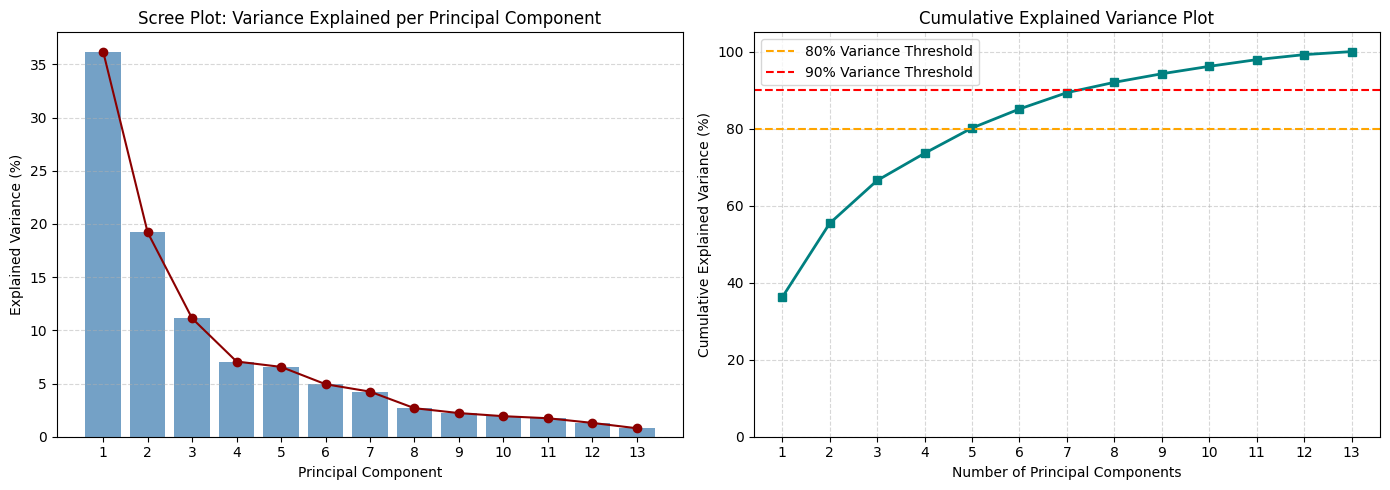

In [6]:
# 5. Scree Plot & Cumulative Explained Variance Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
components = np.arange(1, len(explained_var) + 1)

# Scree Plot
axes[0].bar(components, explained_var * 100, alpha=0.75, color="steelblue", label="Individual Variance")
axes[0].plot(components, explained_var * 100, marker="o", color="darkred")
axes[0].set_title("Scree Plot: Variance Explained per Principal Component")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_xticks(components)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Cumulative Explained Variance Plot
axes[1].plot(components, cum_var * 100, marker="s", color="teal", linewidth=2)
axes[1].axhline(80, color="orange", linestyle="--", label="80% Variance Threshold")
axes[1].axhline(90, color="red", linestyle="--", label="90% Variance Threshold")
axes[1].set_title("Cumulative Explained Variance Plot")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance (%)")
axes[1].set_xticks(components)
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

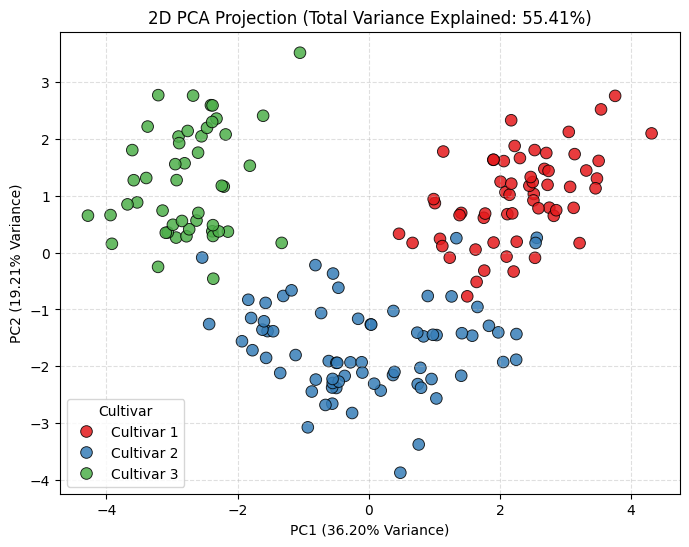

In [7]:
# 6. 2D PCA Visualization
pca_2d = PCA(n_components=2)
coords_2d = pca_2d.fit_transform(X_scaled)
df_pca2d = pd.DataFrame(coords_2d, columns=["PC1", "PC2"])
df_pca2d["Cultivar"] = y

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca2d, x="PC1", y="PC2", hue="Cultivar",
    palette="Set1", s=70, alpha=0.85, edgecolor="k"
)
plt.title(
    f"2D PCA Projection (Total Variance Explained: {sum(pca_2d.explained_variance_ratio_)*100:.2f}%)"
)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% Variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% Variance)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

In [8]:
# 7. Interactive 3D PCA Visualization
pca_3d = PCA(n_components=3)
coords_3d = pca_3d.fit_transform(X_scaled)
df_pca3d = pd.DataFrame(coords_3d, columns=["PC1", "PC2", "PC3"])
df_pca3d["Cultivar"] = y

fig_3d = px.scatter_3d(
    df_pca3d,
    x="PC1", y="PC2", z="PC3",
    color="Cultivar",
    title=f"3D PCA Projection (Total Variance Explained: {sum(pca_3d.explained_variance_ratio_)*100:.2f}%)",
    labels={
        "PC1": f"PC1 ({pca_3d.explained_variance_ratio_[0]*100:.1f}%)",
        "PC2": f"PC2 ({pca_3d.explained_variance_ratio_[1]*100:.1f}%)",
        "PC3": f"PC3 ({pca_3d.explained_variance_ratio_[2]*100:.1f}%)"
    },
    opacity=0.85
)
fig_3d.update_traces(marker=dict(size=5))
fig_3d.show()